# ETH primary strategies with trading fees: L10, L03, A12L, L1

This notebook is the same as `strategii_primare.ipynb` (same data, events, rules, exits and statistics), translated to English, with **one change: trading fees are applied to every trade**.

**Fee assumption:** `COST_BPS_ROUNDTRIP = 10` bps per round trip = OKX USDT perpetual taker fee of 0.05% on entry + 0.05% on exit (Lv1 regular user). Change it in the configuration cell (e.g. 4 bps for maker/maker, 20 bps for spot taker). Section 15 (new) shows gross vs net side by side.

| Strategy | Events | Rule | Side |
|---|---|---|---|
| **L10_capitulation** | fixed CUSUM 0.05 | **down** event + move faster than the median of the last 100 moves + notional/s during the move > 2× its 7-day median | LONG |
| **L03_fast_dn_reversal** | fixed CUSUM 0.05 | **down** event + move faster than the median of the last 100 moves | LONG |
| **A12L_persistent_us_demand** | dynamic CUSUM (σ_bar·√15) | **up** event + Coinbase ETH premium (60 min) above its 7-day median + above the median in > 50% of the last 24 h | LONG |
| **L1_spot_led_breakout** | dynamic CUSUM (σ_bar·√15) | **up** event + Coinbase ETH premium (60 min) above its 7-day median | LONG |

### How profit is computed

Gross profit per trade is **`side × ret`**, where `ret` comes from `trend_scanning_labels` (mlfinpy):

$$ret = \frac{close[t_1]}{close[t_0]} - 1$$

Net profit per trade is **`side × ret − fee`**, with `fee = COST_BPS_ROUNDTRIP / 10,000`.

- `t0` = event bar (entry at close).
- `t1` = end of the 10–19 bar window with the largest |t-value| (exit at close). There is no TP / SL.
- **`t_value` is not profit.** It is the trend t-statistic and is used only for *precision* (how often `sign(t_value)` = side, i.e. `bin == side`).

⚠️ `t1` is chosen ex post (the window with the clearest trend), so it is not a 1:1 implementable exit. For an implementable check, set `PNL_MODE = "fixed_bars"` in the configuration cell: the exit then happens after a fixed number of bars.

### How to add a new strategy

Add one line to the `STRATEGIES` list (section 3) with: name, event type, side and a rule written as a `lambda`. The rest of the notebook (backtest, statistics, charts) adapts automatically.

### Exit modes (`PNL_MODE`)

| Mode | Exit | Implementable? |
|---|---|---|
| `"ret"` | at `t1` from trend scanning (10–19 bars, window chosen ex post) | no (uses the future) |
| `"fixed_bars"` | after `FIXED_BARS` bars | yes |
| `"triple_barrier"` | first of: profit-take at `+TB_PT·σ·√TB_MAX_BARS`, stop-loss at `−TB_SL·σ·√TB_MAX_BARS`, or after `TB_MAX_BARS` bars (σ = ex-ante bar volatility) | yes |

Section 16 compares the three modes side by side on the same signals.


## 0. Loading the data

In [49]:
from pathlib import Path
import pandas as pd

def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATASETS_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"
volume_100 = pd.read_parquet(DATASETS_DIR / "SOLUSDT_spot_volume_42100_100pd_20210901-20260901_b2c6c83b/volume.parquet")

In [50]:
def set_datetime_index(df):
    return df.set_index(
        pd.to_datetime(df["bar_end_us"], unit="us", utc=True)
    ).sort_index().rename_axis("datetime")

df = set_datetime_index(volume_100)
df = df[~df.index.duplicated(keep='first')]

In [51]:
# Calculate percentage of missing values
null_pct = df.isna().mean() * 100

# Identify columns with more than 1% missing values
cols_to_drop = null_pct[null_pct > 1]

# Display columns to be removed
print(cols_to_drop.sort_values(ascending=False).to_string())

# Remove columns
df = df.drop(columns=cols_to_drop.index)

print(f"\nRemoved {len(cols_to_drop)} columns.")
print(f"Remaining columns: {df.shape[1]}")

etf_btc_net_flow_total_usd_economic_age_d              100.000000
etf_btc_net_flow_total_usd_age_s                       100.000000
etf_btc_net_flow_total_usd                             100.000000
etf_btc_net_flow_total_usd_z60                         100.000000
etf_btc_sum_reported_funds_usd_economic_age_d          100.000000
etf_btc_sum_reported_funds_usd_age_s                   100.000000
etf_btc_sum_reported_funds_usd                         100.000000
etf_btc_n_funds_reported_age_s                         100.000000
etf_btc_n_funds_reported_economic_age_d                100.000000
etf_eth_net_flow_total_usd                             100.000000
etf_btc_n_funds_reported                               100.000000
etf_eth_net_flow_total_usd_age_s                       100.000000
etf_eth_sum_reported_funds_usd                         100.000000
etf_eth_net_flow_total_usd_z60                         100.000000
etf_eth_net_flow_total_usd_economic_age_d              100.000000
cost_sell_

In [52]:
from mlfinpy.labeling import trend_scanning_labels

tr_scan_labels = trend_scanning_labels(
    price_series=df['close'],
    t_events=df['close'].index,
    look_forward_window=20,
    min_sample_length=10
)

df = pd.concat([df, tr_scan_labels], axis=1)
df = df.loc[:, ~df.columns.duplicated(keep="last")]   # safety in case the labels already existed

## 1. Configuration

All backtest parameters are here. The strategy rules are **not** optimised: they are the ones fixed and tested in reports v1–v3.

**The only parameter changed vs. the original notebook is `COST_BPS_ROUNDTRIP`: 0 → 10 bps (fees applied).**

`PNL_MODE` now also accepts `"triple_barrier"` (default here), configured by `TB_MAX_BARS`, `TB_PT`, `TB_SL`, `TB_VOL_WINDOW`.


In [53]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from dataclasses import dataclass
from typing import Callable
from scipy.stats import norm, skew, kurtosis
from mlfinpy.filters import cusum_filter

# --- periods
SPLIT_DATE = pd.Timestamp("2025-09-01", tz="UTC")   # dev < SPLIT_DATE <= holdout

# --- profit
PNL_MODE = "triple_barrier"   # "ret" = trend-scanning exit at t1 (ex post) | "fixed_bars" = exit after FIXED_BARS bars | "triple_barrier" = TP / SL / time limit
FIXED_BARS = 200
# --- triple barrier (used when PNL_MODE = "triple_barrier")
TB_MAX_BARS = FIXED_BARS  # vertical barrier: max holding period in bars (same horizon as fixed_bars)
TB_PT = 1.0               # profit-take at +TB_PT * sigma * sqrt(TB_MAX_BARS)
TB_SL = 2.0               # stop-loss at  -TB_SL * sigma * sqrt(TB_MAX_BARS)  (wide stop: a tight 1-sigma stop cut trades that later recovered)
TB_VOL_WINDOW = 100       # bars used for the ex-ante bar volatility sigma (up to the previous bar)
# --- trading fees (THE ONLY CHANGE vs. the original notebook)
# OKX USDT perpetual, Lv1 regular user: taker 0.05% per side -> 10 bps round trip (maker 0.02% -> 4 bps; spot taker 0.10% -> 20 bps)
COST_BPS_ROUNDTRIP = 10.0  # round-trip cost in bps applied to every trade (0 = gross)
COST_SCENARIOS_BPS = [0, 5, 10, 20]

# --- money
INITIAL_CAPITAL = 10_000  # USD
TRADE_NOTIONAL = 10_000   # USD invested in every trade (fixed, no compounding)

# --- PSR / DSR
ANN_DAYS = 365            # crypto trades 365 days a year
N_TRIALS = 78             # how many strategies were tested in total in rounds v1–v3 (third law of backtesting)
SR_VAR_TRIALS = 0.000869  # variance of the DAILY Sharpe across the 78 trials (estimated on dev in v1–v3)

REQUIRED = ["close", "notional_usdt", "notional_per_s", "premium_fx_coinbase_btc_1m", "t1", "t_value", "ret", "bin"]
missing = [c for c in REQUIRED if c not in df.columns]
assert not missing, f"Missing required columns: {missing}"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#e4e3df", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
})
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
print(f"Data: {df.index.min()} -> {df.index.max()}, {len(df):,} bars")
print(f"Fees applied: {COST_BPS_ROUNDTRIP} bps round trip per trade")

Data: 2021-09-01 00:03:21.125000+00:00 -> 2026-08-31 22:50:45.508148+00:00, 182,232 bars
Fees applied: 10.0 bps round trip per trade


## 2. Events and features

`cusum_with_runs` uses the same logic as `mlfinpy.filters.cusum_filter` (checked with `assert`), but additionally keeps:
- **`cusum_side`**: +1 if the upward accumulator fired, −1 if the downward one fired;
- **`run_start`**: the bar at which the firing accumulator was last 0, i.e. the start of the move.

From these I compute the duration of the move (`run_hours`), whether it was **fast** (`fast`, below the median of the last 100 moves, using only the past) and the volume **intensity** during the move (`intensity_rel`).

In [54]:
def cusum_with_runs(close: pd.Series, threshold) -> pd.DataFrame:
    """Symmetric CUSUM on log(close), identical to mlfinpy.cusum_filter.
    threshold: float or pd.Series aligned with close."""
    lr = np.log(close).diff().values
    h = np.full(len(close), float(threshold)) if np.isscalar(threshold) else threshold.reindex(close.index).values
    s_pos = s_neg = 0.0
    p_start = n_start = 0
    rows = []
    for i in range(1, len(close)):
        s_pos = max(0.0, s_pos + lr[i])
        s_neg = min(0.0, s_neg + lr[i])
        if s_pos == 0.0:
            p_start = i
        if s_neg == 0.0:
            n_start = i
        if s_neg < -h[i]:
            rows.append((i, -1, n_start)); s_neg, n_start = 0.0, i
        elif s_pos > h[i]:
            rows.append((i, +1, p_start)); s_pos, p_start = 0.0, i
    pos, side, start = map(np.array, zip(*rows))
    ev = pd.DataFrame({"cusum_side": side, "bar_pos": pos, "start_pos": start}, index=close.index[pos])
    ev["run_start"] = close.index[start]
    return ev


def add_run_features(ev: pd.DataFrame, df: pd.DataFrame) -> pd.DataFrame:
    ev = ev.copy()
    dur_s = (ev.index.to_series() - ev["run_start"]).dt.total_seconds()
    ev["run_hours"] = dur_s / 3600
    # fast = shorter than the median of the last 100 moves (previous events only)
    med_prev = ev["run_hours"].shift(1).rolling(100, min_periods=30).median()
    ev["fast"] = (ev["run_hours"] < med_prev) & med_prev.notna()
    # intensity: notional/s during the move relative to the 7-day median of notional/s
    cum_not = np.r_[0.0, df["notional_usdt"].fillna(0).cumsum().values]
    med7 = df["notional_per_s"].rolling("7D").median().values
    ev["intensity_rel"] = (cum_not[ev.bar_pos + 1] - cum_not[ev.start_pos + 1]) / dur_s.clip(lower=1).values / med7[ev.bar_pos]
    return ev


def bar_state_features(df: pd.DataFrame) -> pd.DataFrame:
    """Market state at every bar, computed from the past only."""
    p = df["premium_fx_coinbase_btc_1m"]                 # Coinbase ETH-USD vs Binance ETH-USDT premium, FX-adjusted
    med7 = p.rolling("7D").median()
    S = pd.DataFrame(index=df.index)
    S["cbp_ex_60min"] = p.rolling("60min").mean() - med7     # premium (60 min) above its 7-day norm
    S["cbp_pos_frac_24h"] = (p > med7).astype(float).rolling("24h").mean()   # persistence of US demand over the last 24 h
    return S


close = df["close"]
STATE = bar_state_features(df)

# dynamic threshold: ex-ante σ of one bar (last 100 bars, up to the previous bar) × √15
rv100 = (np.log(close).diff() ** 2).rolling(100).sum()
h_dyn = (np.sqrt(rv100.shift(1) / 100) * np.sqrt(15)).bfill()

EVENTS = {}
for key, thr in {"cusum_005": 0.05, "cusum_dyn": h_dyn}.items():
    ev = cusum_with_runs(close, thr)
    assert ev.index.equals(cusum_filter(close, threshold=thr)), f"{key}: differs from mlfinpy"
    EVENTS[key] = add_run_features(ev, df).join(STATE)
    print(f"{key}: {len(ev):,} events (up {int((ev.cusum_side > 0).sum()):,} / down {int((ev.cusum_side < 0).sum()):,}) - identical to mlfinpy.cusum_filter")

cusum_005: 3,308 events (up 1,657 / down 1,651) - identical to mlfinpy.cusum_filter
cusum_dyn: 15,009 events (up 7,471 / down 7,538) - identical to mlfinpy.cusum_filter


## 3. The strategies

Each strategy is a `Strategy` object. To add a new one, write one line in the list. `rule` receives the event table and returns a boolean mask.

In [55]:
@dataclass
class Strategy:
    name: str
    events: str                                   # key in EVENTS
    side: int                                     # +1 long / -1 short
    rule: Callable[[pd.DataFrame], pd.Series]     # condition on the event table
    description: str = ""


STRATEGIES = [
    Strategy("L10_capitulation", "cusum_005", +1,
             lambda e: (e.cusum_side == -1) & e.fast & (e.intensity_rel > 2),
             "Fast 5% drop on volume > 2x normal = forced selling -> rebound"),
    Strategy("L03_fast_dn_reversal", "cusum_005", +1,
             lambda e: (e.cusum_side == -1) & e.fast,
             "5% drop faster than usual = forced flow -> rebound"),
    Strategy("A12L_persistent_us_demand", "cusum_dyn", +1,
             lambda e: (e.cusum_side == 1) & (e.cbp_ex_60min > 0) & (e.cbp_pos_frac_24h > 0.5),
             "Rise backed by persistent US demand (Coinbase premium) -> continuation"),
    Strategy("L1_spot_led_breakout", "cusum_dyn", +1,
             lambda e: (e.cusum_side == 1) & (e.cbp_ex_60min > 0),
             "Rise confirmed by above-normal Coinbase premium -> continuation"),
]
NAMES = [s.name for s in STRATEGIES]
COLOR = dict(zip(NAMES, COLORS))

## 4. Trades

One row = one trade. `gross_ret = side × ret`, `net_ret = gross_ret − fee` (fee = `COST_BPS_ROUNDTRIP` / 10,000), `pnl_usd = TRADE_NOTIONAL × net_ret`.

With `PNL_MODE = "triple_barrier"`, each trade exits at the first barrier touched (`exit_reason` = `take_profit`, `stop_loss` or `time`).


In [56]:
def fixed_bars_exit(df, entry_times, n):
    pos = df.index.get_indexer(entry_times)
    out = np.minimum(pos + n, len(df) - 1)
    ret = df["close"].values[out] / df["close"].values[pos] - 1
    ret[pos + n >= len(df)] = np.nan
    return df.index[out], ret


def triple_barrier_exit(df, entry_times, side, max_bars, pt_mult, sl_mult, vol_window):
    """Triple-barrier exit on close prices (same first-touch logic as mlfinpy.labeling.get_events).
    Barriers: +pt_mult*sigma*sqrt(max_bars) (profit) and -sl_mult*sigma*sqrt(max_bars) (loss), in the trade's direction;
    sigma = ex-ante volatility of one bar (last vol_window log returns, up to the previous bar). Vertical barrier: max_bars."""
    close = df["close"].values
    lr = np.log(df["close"]).diff()
    sigma = np.sqrt((lr ** 2).rolling(vol_window).mean().shift(1)).values
    pos = df.index.get_indexer(entry_times)
    n = len(close)
    exit_pos = np.full(len(pos), -1)
    reason = np.empty(len(pos), dtype=object)
    for k, p0 in enumerate(pos):
        if p0 + max_bars >= n or not np.isfinite(sigma[p0]):
            reason[k] = "incomplete"; continue
        width = sigma[p0] * np.sqrt(max_bars)
        path = (close[p0 + 1:p0 + max_bars + 1] / close[p0] - 1) * side
        hit_pt = np.flatnonzero(path >= pt_mult * width) if pt_mult > 0 else np.array([], int)
        hit_sl = np.flatnonzero(path <= -sl_mult * width) if sl_mult > 0 else np.array([], int)
        cands = [(max_bars - 1, "time")]
        if len(hit_pt): cands.append((hit_pt[0], "take_profit"))
        if len(hit_sl): cands.append((hit_sl[0], "stop_loss"))
        j, why = min(cands, key=lambda c: c[0])
        exit_pos[k], reason[k] = p0 + 1 + j, why
    ok = exit_pos >= 0
    t1 = pd.Series(pd.NaT, index=range(len(pos)), dtype=df.index.dtype)
    t1[ok] = df.index[exit_pos[ok]]
    ret = np.full(len(pos), np.nan)
    ret[ok] = close[exit_pos[ok]] / close[pos[ok]] - 1
    return t1.values, ret, reason


def build_trades(strategies, events, df, mode=None):
    mode = mode or PNL_MODE
    rows = []
    for s in strategies:
        E = events[s.events]
        sel = E[s.rule(E).fillna(False).astype(bool)]
        T = pd.DataFrame(index=sel.index)
        T["strategy"], T["side"] = s.name, s.side
        T["t0"] = sel.index
        T["exit_reason"] = "t1" if mode == "ret" else "time"
        if mode == "ret":
            lab = df.loc[sel.index, ["t1", "ret", "t_value", "bin"]]
            T["t1"] = pd.to_datetime(lab["t1"], utc=True)
            T["ret"] = lab["ret"].astype(float)
        elif mode == "fixed_bars":
            T["t1"], T["ret"] = fixed_bars_exit(df, sel.index, FIXED_BARS)
            lab = df.loc[sel.index, ["t_value", "bin"]]
        elif mode == "triple_barrier":
            t1, ret, why = triple_barrier_exit(df, sel.index, s.side, TB_MAX_BARS, TB_PT, TB_SL, TB_VOL_WINDOW)
            T["t1"], T["ret"], T["exit_reason"] = pd.to_datetime(t1, utc=True), ret, why
            lab = df.loc[sel.index, ["t_value", "bin"]]
        else:
            raise ValueError(f"unknown PNL_MODE: {mode}")
        T["t_value"], T["bin"] = lab["t_value"].astype(float), lab["bin"].astype(float)
        rows.append(T)
    T = pd.concat(rows).dropna(subset=["t1", "ret"])
    T["gross_ret"] = T.side * T.ret
    T["net_ret"] = T.gross_ret - COST_BPS_ROUNDTRIP / 1e4
    T["pnl_usd"] = TRADE_NOTIONAL * T.net_ret
    T["hold_hours"] = (T.t1 - T.t0).dt.total_seconds() / 3600
    T["period"] = np.where(T.t0 < SPLIT_DATE, "dev", "holdout")
    T["trend_correct"] = (T.bin == T.side)
    return T.reset_index(drop=True)


TRADES = build_trades(STRATEGIES, EVENTS, df)
print(f"Exit mode: {PNL_MODE}\n")
print(TRADES.groupby(["strategy", "period"]).size().unstack().reindex(NAMES).to_string())
if PNL_MODE == "triple_barrier":
    print("\nExit reasons (% of trades):")
    print((TRADES.groupby("strategy").exit_reason.value_counts(normalize=True).unstack().reindex(NAMES) * 100).round(1).to_string())
TRADES.head()

Exit mode: triple_barrier

period                      dev  holdout
strategy                                
L10_capitulation            249       26
L03_fast_dn_reversal        681       84
A12L_persistent_us_demand  2103      336
L1_spot_led_breakout       3314      557

Exit reasons (% of trades):
exit_reason                stop_loss  take_profit  time
strategy                                               
L10_capitulation                 5.5         36.7  57.8
L03_fast_dn_reversal             4.8         32.9  62.2
A12L_persistent_us_demand        5.1         31.8  63.1
L1_spot_led_breakout             4.8         32.7  62.6


,strategy,side,t0,exit_reason,t1,ret,t_value,bin,gross_ret,net_ret,pnl_usd,hold_hours,period,trend_correct
0,L10_capitulation,1,2021-09-07 08:32:28.793000+00:00,stop_loss,2021-09-07 15:08:35.113000+00:00,-0.223945,-3.871769,-1.0,-0.223945,-0.224945,-2249.448276,6.601756,dev,False
1,L10_capitulation,1,2021-09-07 08:44:11.725000+00:00,stop_loss,2021-09-07 15:08:53.225000+00:00,-0.219714,4.342293,1.0,-0.219714,-0.220714,-2207.136875,6.411528,dev,True
2,L10_capitulation,1,2021-09-07 14:47:15.418000+00:00,take_profit,2021-09-07 16:18:43.534000+00:00,0.111939,-1.540804,-1.0,0.111939,0.110939,1109.393939,1.524477,dev,False
3,L10_capitulation,1,2021-09-07 14:49:02.823000+00:00,take_profit,2021-09-07 16:12:16.788000+00:00,0.121603,10.944133,1.0,0.121603,0.120603,1206.025641,1.387212,dev,True
4,L10_capitulation,1,2021-09-07 14:59:39.732000+00:00,take_profit,2021-09-07 16:12:16.788000+00:00,0.131028,-6.400733,-1.0,0.131028,0.130028,1300.277957,1.210293,dev,False


## 5. PSR and DSR: are they worth using?

**Yes, both**, for different reasons:

- **PSR** (probability that the true Sharpe is > 0) is needed here because returns are not Gaussian. The daily PnL of these strategies has kurtosis of 10–100 (many days without trades, a few days with large moves), and the track records differ a lot between strategies (~28 trades per year for L10, ~800 for L1). The plain Sharpe puts them on the same footing; PSR does not.
- **DSR** is essential because these 4 strategies were selected from **78 trials** (v1–v3). The Sharpe of the best of 78 strategies with no edge would be positive anyway. DSR compares the Sharpe with the maximum expected from pure chance: `N_TRIALS = 78` and `SR_VAR_TRIALS` = variance of the daily Sharpes across the 78 trials.

**Reading:** ≥ 0.95 means significant at 5%.
- On **holdout**, PSR is the relevant test: nothing was selected on this period in the round in which the strategies were chosen.
- On **dev / full**, DSR is the right test, because the selection was made there.

⚠️ If you test other variants, increase `N_TRIALS` (third law of backtesting).

Both are computed on the **daily PnL** (days without trades = 0), with the non-annualised Sharpe in the formula. With fees applied, they are computed on the **net** PnL.

In [57]:
EULER = 0.5772156649

def psr(sr, T, g3, g4, sr_star=0.0):
    """Probabilistic Sharpe Ratio (Bailey & López de Prado 2012). sr on the base period (daily), g4 = kurtosis (normal = 3)."""
    den = np.sqrt(max(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2, 1e-12))
    return float(norm.cdf((sr - sr_star) * np.sqrt(T - 1) / den))


def expected_max_sr(n_trials, sr_var):
    """SR* = expected maximum Sharpe across N trials with no edge (Bailey & López de Prado 2014)."""
    return np.sqrt(sr_var) * ((1 - EULER) * norm.ppf(1 - 1 / n_trials) + EULER * norm.ppf(1 - 1 / (n_trials * np.e)))


SR_STAR_DSR = expected_max_sr(N_TRIALS, SR_VAR_TRIALS)
print(f"SR* (DSR) = {SR_STAR_DSR:.4f} daily = {SR_STAR_DSR * np.sqrt(ANN_DAYS):.2f} annualised")

SR* (DSR) = 0.0720 daily = 1.38 annualised


## 6. Economic statistics (net of fees)

In [58]:
def daily_pnl(T, start, end):
    days = pd.date_range(start.floor("D"), end.floor("D"), freq="D", tz="UTC")
    return T.groupby(T.t1.dt.floor("D")).pnl_usd.sum().reindex(days, fill_value=0.0)


def max_concurrent(T):
    ev = pd.concat([pd.Series(1, index=T.t0), pd.Series(-1, index=T.t1)]).sort_index(kind="stable")
    return int(ev.cumsum().max()) if len(ev) else 0


def exposure(T, start, end):
    iv = T[["t0", "t1"]].sort_values("t0").values
    tot, cur_s, cur_e = 0.0, None, None
    for s, e in iv:
        if cur_e is None or s > cur_e:
            if cur_e is not None:
                tot += (cur_e - cur_s).total_seconds()
            cur_s, cur_e = s, e
        else:
            cur_e = max(cur_e, e)
    if cur_e is not None:
        tot += (cur_e - cur_s).total_seconds()
    return tot / (end - start).total_seconds()


def stats(T, start, end):
    d = daily_pnl(T, start, end)
    r = d / INITIAL_CAPITAL                                     # daily return on capital
    years = (end - start).days / 365.25
    eq = d.cumsum()
    dd = eq - eq.cummax()
    sr_d = r.mean() / r.std() if r.std() > 0 else np.nan
    downside = np.sqrt(np.mean(np.minimum(r, 0) ** 2))         # downside deviation (target 0)
    wins, losses = T.net_ret[T.net_ret > 0], T.net_ret[T.net_ret <= 0]
    g3, g4 = skew(r), kurtosis(r, fisher=False)
    ann_ret = d.sum() / INITIAL_CAPITAL / years
    max_dd = dd.min()
    return {
        "trades": len(T),
        "trades / month": len(T) / (years * 12),
        "trades / week": len(T) / (years * 52.18),
        "win rate": (T.net_ret > 0).mean(),
        "trend correct (bin = side)": T.trend_correct.mean(),
        "mean t_value (× side)": (T.side * T.t_value).mean(),
        "mean / trade (bps)": T.net_ret.mean() * 1e4,
        "median / trade (bps)": T.net_ret.median() * 1e4,
        "average win (bps)": wins.mean() * 1e4,
        "average loss (bps)": losses.mean() * 1e4,
        "profit factor": wins.sum() / -losses.sum() if losses.sum() < 0 else np.nan,
        "PnL total (USD)": d.sum(),
        "PnL / year (USD)": d.sum() / years,
        "annual return (% capital)": ann_ret * 100,
        "annualised Sharpe": sr_d * np.sqrt(ANN_DAYS),
        "annualised Sortino": r.mean() / downside * np.sqrt(ANN_DAYS) if downside > 0 else np.nan,
        "max drawdown (USD)": max_dd,
        "max drawdown (% capital)": max_dd / INITIAL_CAPITAL * 100,
        "Calmar": ann_ret / (-max_dd / INITIAL_CAPITAL) if max_dd < 0 else np.nan,
        "days with PnL ≠ 0 (%)": (d != 0).mean() * 100,
        "average trade duration (h)": T.hold_hours.mean(),
        "exposure (% time)": exposure(T, start, end) * 100,
        "max concurrent positions": max_concurrent(T),
        "daily PnL skew": g3,
        "daily PnL kurtosis": g4,
        "PSR (SR* = 0)": psr(sr_d, len(r), g3, g4, 0.0),
        f"DSR (N = {N_TRIALS})": psr(sr_d, len(r), g3, g4, SR_STAR_DSR),
    }


PERIODS = {
    "FULL": (df.index.min(), df.index.max()),
    "DEV": (df.index.min(), SPLIT_DATE - pd.Timedelta("1ns")),
    "HOLDOUT": (SPLIT_DATE, df.index.max()),
}
STATS = {}
for pname, (a, b) in PERIODS.items():
    STATS[pname] = pd.DataFrame({n: stats(TRADES[(TRADES.strategy == n) & (TRADES.t0 >= a) & (TRADES.t0 <= b)], a, b)
                                 for n in NAMES})

fmt = lambda x: f"{x:,.2f}" if isinstance(x, (float, np.floating)) else f"{x:,}"
for pname, S in STATS.items():
    print(f"\n================ {pname}  ({PERIODS[pname][0].date()} -> {PERIODS[pname][1].date()}) ================")
    print(S.map(fmt).to_string())


================ FULL  (2021-09-01 -> 2026-08-31) ================
                           L10_capitulation L03_fast_dn_reversal A12L_persistent_us_demand L1_spot_led_breakout
trades                               275.00               765.00                  2,439.00             3,871.00
trades / month                         4.59                12.76                     40.68                64.56
trades / week                          1.05                 2.93                      9.35                14.85
win rate                               0.60                 0.57                      0.53                 0.54
trend correct (bin = side)             0.63                 0.56                      0.51                 0.51
mean t_value (× side)                  1.66                 0.84                      0.21                 0.16
mean / trade (bps)                   178.41                72.63                     -2.21                10.67
median / trade (bps)                

**How to read:**
- `win rate` = % of trades with a profit **after fees**.
- `trend correct` = % where `sign(t_value)` = side (not affected by fees).
- `profit factor` = Σ wins / Σ losses (net).
- `annual return` = annual net PnL / `INITIAL_CAPITAL`, no compounding.
- `max concurrent positions` > 1 means that, at that moment, the committed capital exceeded `TRADE_NOTIONAL`.

## 7. Evolution of the money (net of fees)

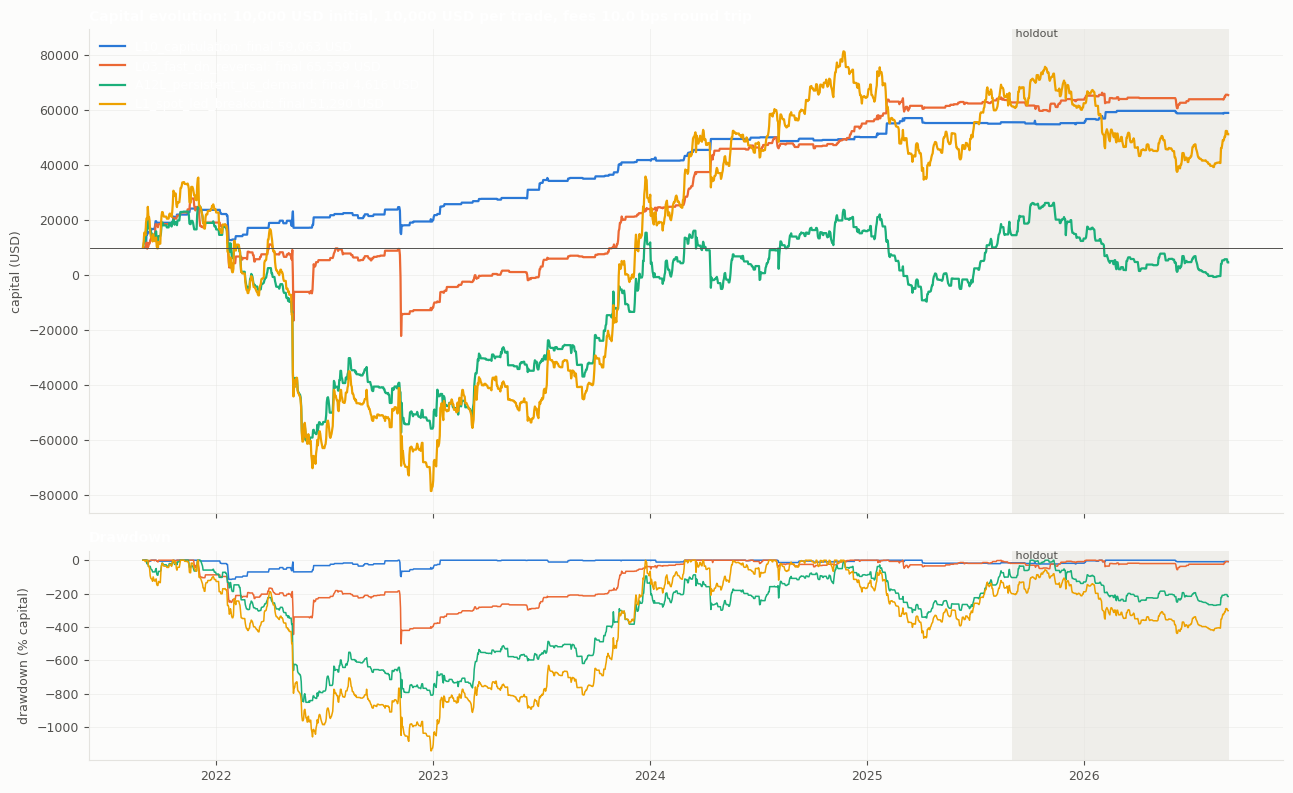

In [59]:
def shade_holdout(ax):
    ax.axvspan(SPLIT_DATE, df.index.max(), color="#efeeea", lw=0, zorder=0)
    ax.text(SPLIT_DATE, 1.0, " holdout", transform=ax.get_xaxis_transform(), va="top", fontsize=8, color="#52514e")

start, end = df.index.min(), df.index.max()
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
for n in NAMES:
    d = daily_pnl(TRADES[TRADES.strategy == n], start, end)
    eq = INITIAL_CAPITAL + d.cumsum()
    axes[0].plot(eq.index, eq.values, color=COLOR[n], lw=1.6, label=f"{n}: final {eq.iloc[-1]:,.0f} USD")
    dd = (d.cumsum() - d.cumsum().cummax()) / INITIAL_CAPITAL * 100
    axes[1].plot(dd.index, dd.values, color=COLOR[n], lw=1.1)
axes[0].axhline(INITIAL_CAPITAL, color="#52514e", lw=0.7)
axes[0].set_ylabel("capital (USD)")
axes[0].set_title(f"Capital evolution: {INITIAL_CAPITAL:,} USD initial, {TRADE_NOTIONAL:,} USD per trade, fees {COST_BPS_ROUNDTRIP} bps round trip", loc="left")
axes[0].legend(frameon=False, loc="upper left")
axes[1].set_ylabel("drawdown (% capital)")
axes[1].set_title("Drawdown", loc="left")
for ax in axes:
    shade_holdout(ax)
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

## 8. How much money each strategy makes: per year, quarter and month (net of fees)

PnL per year (USD):
strategy  L10_capitulation  L03_fast_dn_reversal  A12L_persistent_us_demand  L1_spot_led_breakout
t1                                                                                               
2021               13755.0                9128.0                     7761.0               13941.0
2022               -4261.0              -31468.0                   -73684.0             -101261.0
2023               22403.0               36415.0                    67146.0              103916.0
2024                8350.0               31956.0                     4766.0               38252.0
2025                5169.0                7885.0                    -2677.0               -2253.0
2026                3648.0                1643.0                    -8695.0              -11305.0


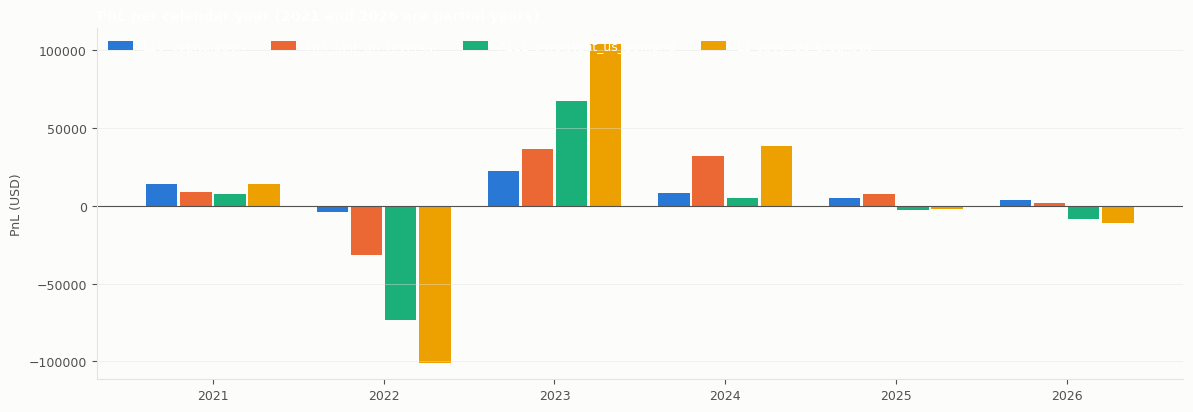

In [60]:
def pnl_by(freq_label):
    T = TRADES.copy()
    if freq_label == "year":
        key = T.t1.dt.year
    elif freq_label == "quarter":
        key = T.t1.dt.tz_localize(None).dt.to_period("Q").astype(str)
    else:
        key = T.t1.dt.tz_localize(None).dt.to_period("M").astype(str)
    return T.pivot_table(index=key, columns="strategy", values="pnl_usd", aggfunc="sum", fill_value=0.0)[NAMES]

PNL_Y, PNL_Q, PNL_M = pnl_by("year"), pnl_by("quarter"), pnl_by("month")
print("PnL per year (USD):"); print(PNL_Y.round(0).to_string())

fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(PNL_Y)); w = 0.8 / len(NAMES)
for k, n in enumerate(NAMES):
    ax.bar(x + (k - (len(NAMES) - 1) / 2) * w, PNL_Y[n].values, width=w * 0.92, color=COLOR[n], label=n)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(x, PNL_Y.index.astype(str)); ax.set_ylabel("PnL (USD)")
ax.set_title("PnL per calendar year (2021 and 2026 are partial years)", loc="left")
ax.legend(frameon=False, ncol=4, loc="upper left"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

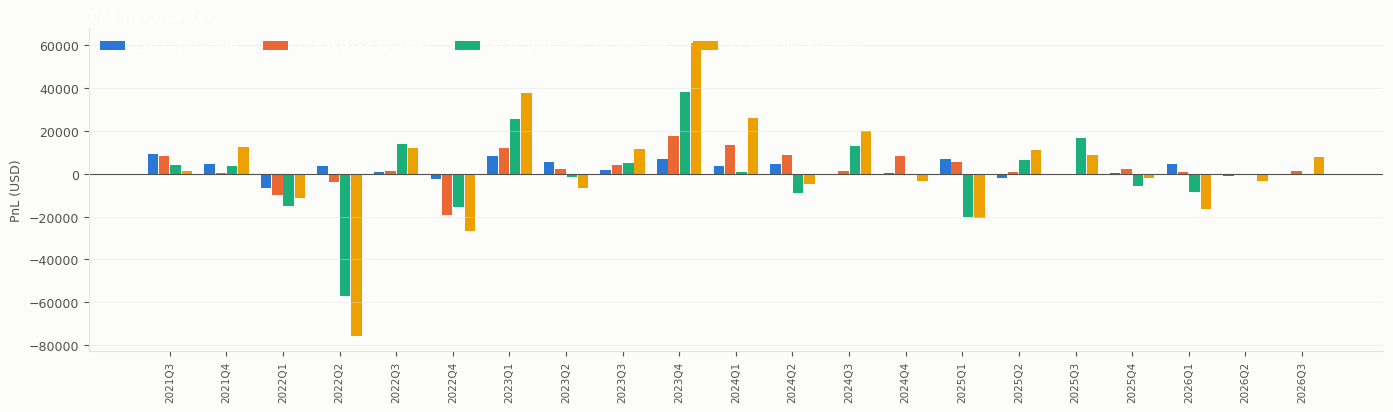

Profitable quarters (% of quarters with at least one trade):
strategy
L10_capitulation             71%
L03_fast_dn_reversal         76%
A12L_persistent_us_demand    48%
L1_spot_led_breakout         52%


In [61]:
fig, ax = plt.subplots(figsize=(14, 4.2))
x = np.arange(len(PNL_Q)); w = 0.8 / len(NAMES)
for k, n in enumerate(NAMES):
    ax.bar(x + (k - (len(NAMES) - 1) / 2) * w, PNL_Q[n].values, width=w * 0.92, color=COLOR[n], label=n)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(x, PNL_Q.index, rotation=90, fontsize=7.5); ax.set_ylabel("PnL (USD)")
ax.set_title("PnL per quarter", loc="left"); ax.legend(frameon=False, ncol=4, loc="upper left"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print("Profitable quarters (% of quarters with at least one trade):")
act = TRADES.assign(q=TRADES.t1.dt.tz_localize(None).dt.to_period("Q").astype(str)).groupby(["strategy", "q"]).pnl_usd.sum()
print((act > 0).groupby(level=0).mean().reindex(NAMES).map("{:.0%}".format).to_string())

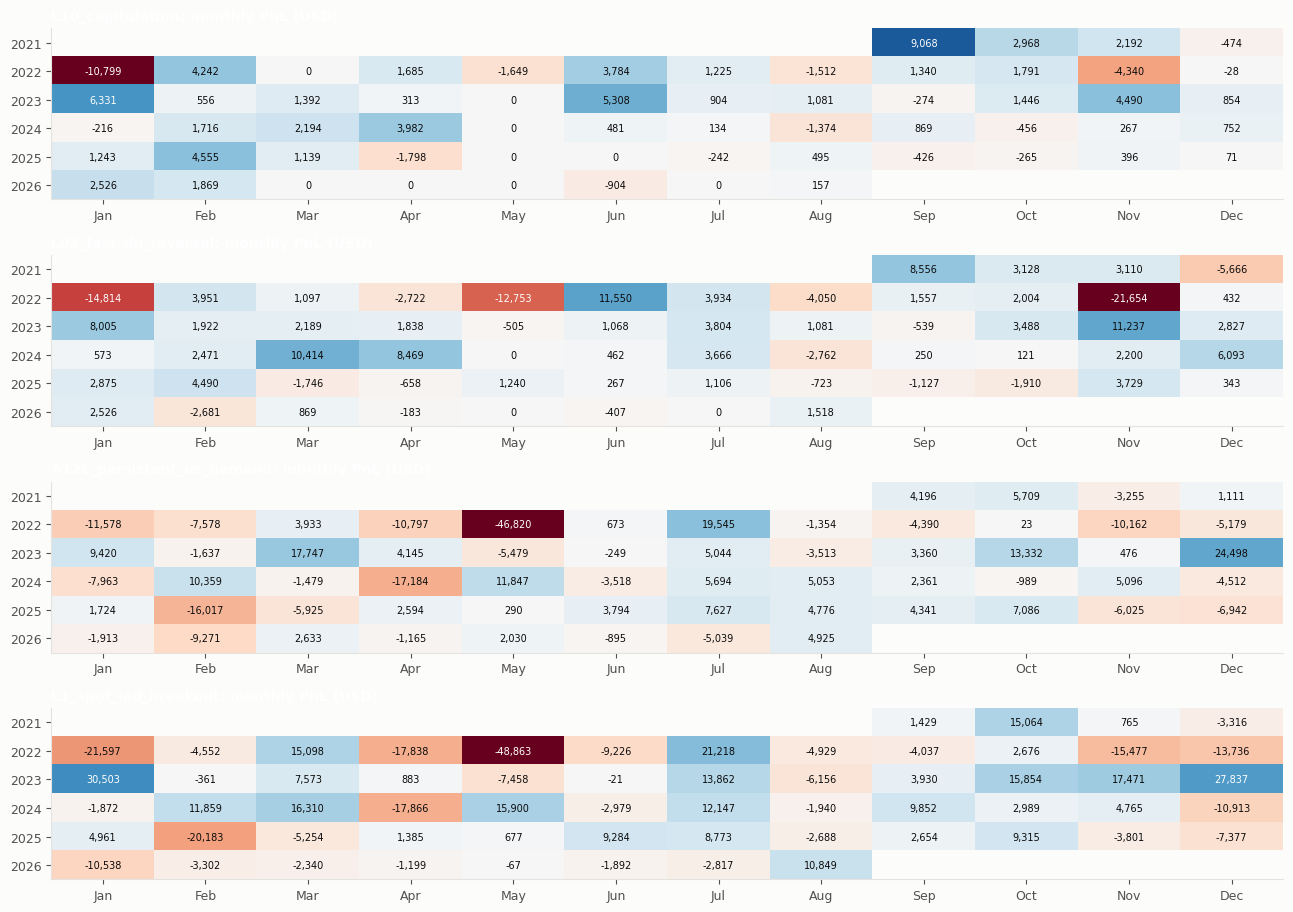

In [62]:
# monthly heatmap: rows = years, columns = months, values = PnL in USD
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(len(NAMES), 1, figsize=(13, 2.3 * len(NAMES)))
for ax, n in zip(np.atleast_1d(axes), NAMES):
    s = PNL_M[n]
    idx = pd.PeriodIndex(s.index, freq="M")
    H = pd.DataFrame({"y": idx.year, "m": idx.month, "v": s.values}).pivot(index="y", columns="m", values="v").reindex(columns=range(1, 13))
    lim = np.nanmax(np.abs(H.values)) or 1
    im = ax.imshow(H.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
    for (i, j), v in np.ndenumerate(H.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.55 * lim else "#0b0b0b")
    ax.set_xticks(range(12), months); ax.set_yticks(range(len(H)), H.index); ax.grid(False)
    ax.set_title(f"{n}: monthly PnL (USD)", loc="left")
plt.tight_layout(); plt.show()

## 9. How many signals each strategy generates

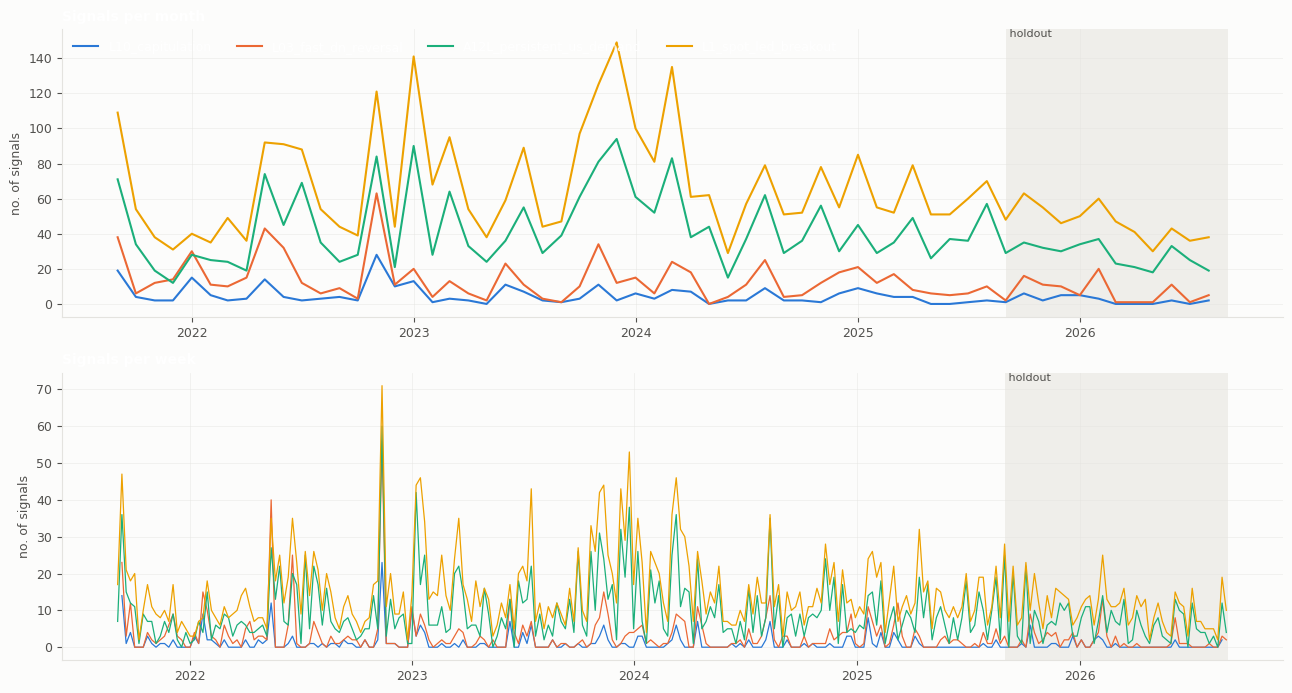

,total,mean / month,max / month,mean / week (with a signal),months without any signal
strategy,,,,,
L10_capitulation,275,5.3,28,2.8,8
L03_fast_dn_reversal,765,13.0,63,4.4,1
A12L_persistent_us_demand,2439,40.6,94,9.6,0
L1_spot_led_breakout,3871,64.5,149,14.8,0


In [63]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for n in NAMES:
    t = TRADES[TRADES.strategy == n].set_index("t0")
    m = t.resample("MS").size(); wk = t.resample("W").size()
    axes[0].plot(m.index, m.values, color=COLOR[n], lw=1.5, label=n)
    axes[1].plot(wk.index, wk.values, color=COLOR[n], lw=0.9, label=n)
axes[0].set_title("Signals per month", loc="left"); axes[1].set_title("Signals per week", loc="left")
for ax in axes:
    shade_holdout(ax); ax.set_ylabel("no. of signals")
axes[0].legend(frameon=False, ncol=4, loc="upper left")
plt.tight_layout(); plt.show()

cnt = TRADES.assign(m=TRADES.t0.dt.tz_localize(None).dt.to_period("M"), w=TRADES.t0.dt.tz_localize(None).dt.to_period("W"))
summary = pd.DataFrame({
    "total": TRADES.groupby("strategy").size(),
    "mean / month": cnt.groupby(["strategy", "m"]).size().groupby(level=0).mean(),
    "max / month": cnt.groupby(["strategy", "m"]).size().groupby(level=0).max(),
    "mean / week (with a signal)": cnt.groupby(["strategy", "w"]).size().groupby(level=0).mean(),
    "months without any signal": [len(pd.period_range(df.index.min().tz_localize(None), df.index.max().tz_localize(None), freq="M"))
                                 - cnt[cnt.strategy == n].m.nunique() for n in sorted(TRADES.strategy.unique())],
}).reindex(NAMES)
summary.round(1)

## 10. Trade quality: win rate per year and return distribution (net of fees)

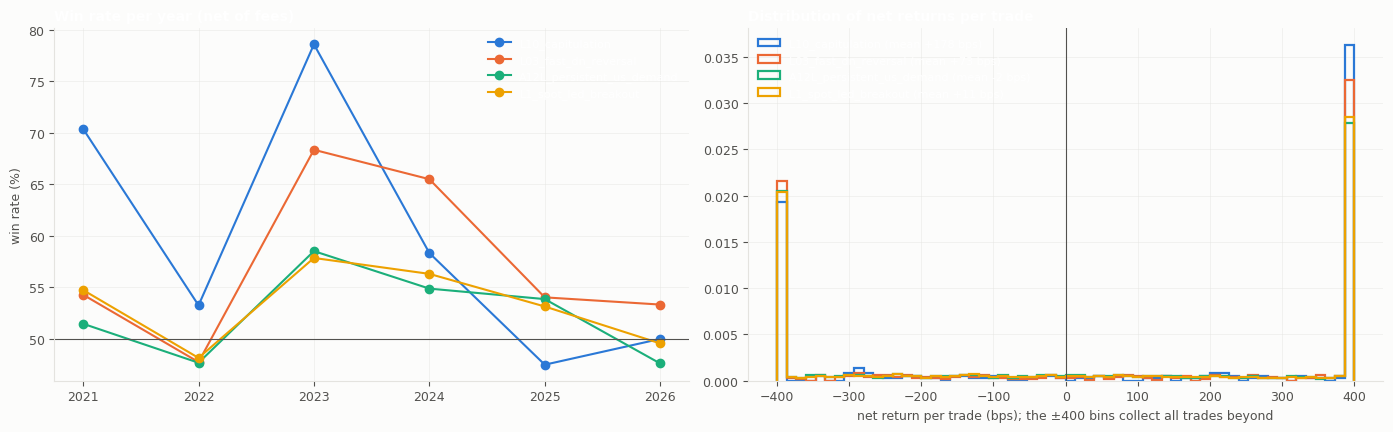

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
wr = TRADES.groupby([TRADES.t0.dt.year, "strategy"]).net_ret.apply(lambda s: (s > 0).mean()).unstack()[NAMES]
for n in NAMES:
    axes[0].plot(wr.index, wr[n] * 100, marker="o", ms=6, color=COLOR[n], label=n)
axes[0].axhline(50, color="#52514e", lw=0.8); axes[0].set_ylabel("win rate (%)")
axes[0].set_title("Win rate per year (net of fees)", loc="left"); axes[0].legend(frameon=False, fontsize=8)

bins = np.linspace(-400, 400, 61)
for n in NAMES:
    v = TRADES.loc[TRADES.strategy == n, "net_ret"] * 1e4
    axes[1].hist(v.clip(-400, 400), bins=bins, density=True, histtype="step", lw=1.6, color=COLOR[n], label=f"{n} (mean {v.mean():+.0f} bps)")
axes[1].axvline(0, color="#52514e", lw=0.8); axes[1].set_xlabel("net return per trade (bps); the ±400 bins collect all trades beyond")
axes[1].set_title("Distribution of net returns per trade", loc="left"); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 11. Stability: Sharpe on rolling 180-day windows (net of fees)

Shows whether the profit comes steadily or only from a few periods.

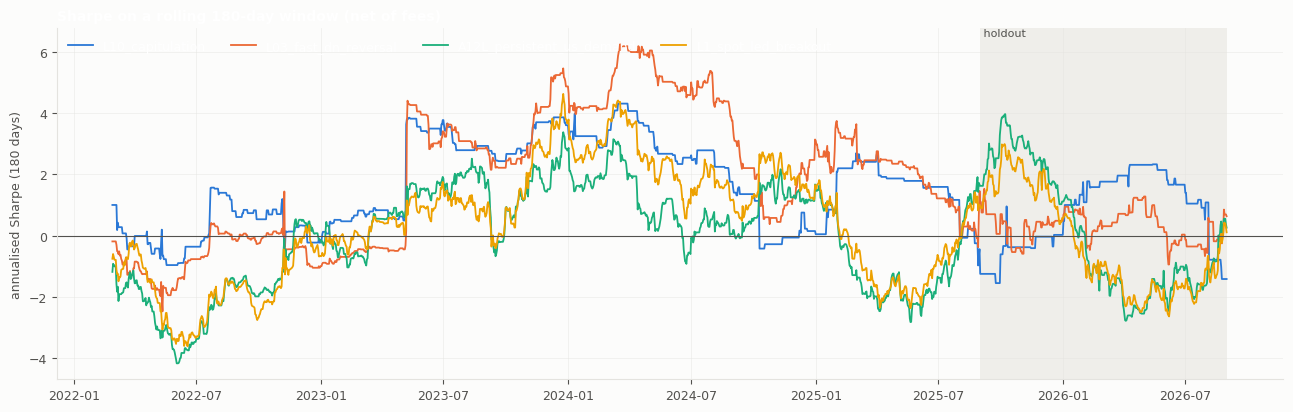

In [65]:
fig, ax = plt.subplots(figsize=(13, 4.2))
for n in NAMES:
    r = daily_pnl(TRADES[TRADES.strategy == n], start, end) / INITIAL_CAPITAL
    rs = r.rolling(180).mean() / r.rolling(180).std() * np.sqrt(ANN_DAYS)
    ax.plot(rs.index, rs.values, color=COLOR[n], lw=1.3, label=n)
ax.axhline(0, color="#52514e", lw=0.8); shade_holdout(ax)
ax.set_ylabel("annualised Sharpe (180 days)"); ax.set_title("Sharpe on a rolling 180-day window (net of fees)", loc="left")
ax.legend(frameon=False, ncol=4, loc="upper left")
plt.tight_layout(); plt.show()

## 12. How different the strategies are from each other

Correlation of daily PnL and signal overlap. L10 is a subset of L03, and A12L is a subset of L1. If you combine them, the overlap matters.

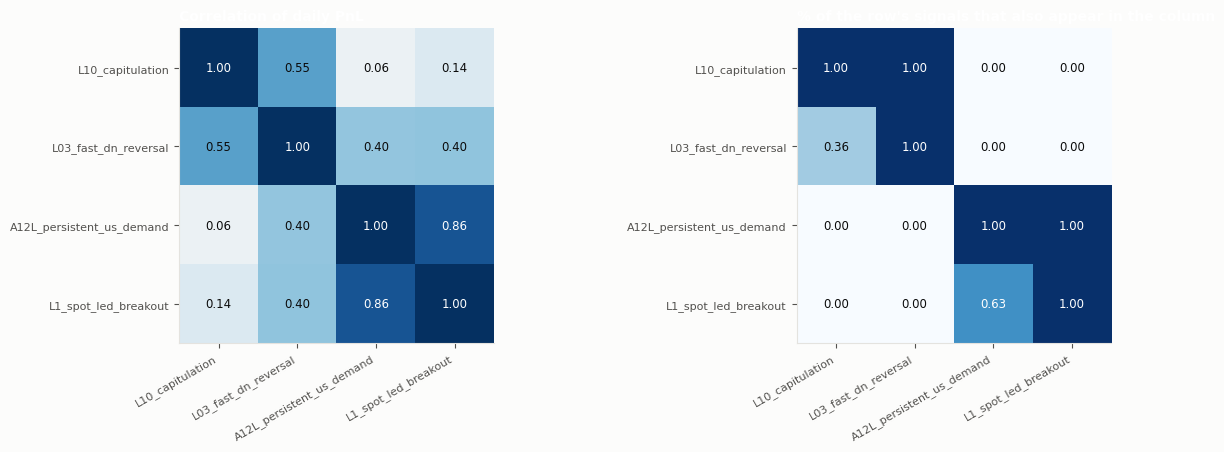

In [66]:
DP = pd.DataFrame({n: daily_pnl(TRADES[TRADES.strategy == n], start, end) for n in NAMES})
corr = DP[(DP != 0).any(axis=1)].corr()
sets = {n: set(TRADES.loc[TRADES.strategy == n, "t0"]) for n in NAMES}
overlap = pd.DataFrame({a: {b: len(sets[a] & sets[b]) / len(sets[a]) for b in NAMES} for a in NAMES}).T

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, M, ttl, cm, vmin in ((axes[0], corr, "Correlation of daily PnL", "RdBu", -1),
                             (axes[1], overlap, "% of the row's signals that also appear in the column", "Blues", 0)):
    ax.imshow(M.values, cmap=cm, vmin=vmin, vmax=1)
    for (i, j), v in np.ndenumerate(M.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(v) > 0.6 else "#0b0b0b")
    ax.set_xticks(range(len(NAMES)), NAMES, rotation=30, ha="right", fontsize=8); ax.set_yticks(range(len(NAMES)), NAMES, fontsize=8)
    ax.set_title(ttl, loc="left"); ax.grid(False)
plt.tight_layout(); plt.show()

## 13. Sensitivity to costs

How much of the annual PnL (USD) remains at different round-trip costs. These scenarios always start from the **gross** return, independently of `COST_BPS_ROUNDTRIP`. OKX perpetual: taker ~10 bps, maker ~4 bps round trip; Binance spot taker ~20 bps.

Annual PnL (USD) after costs, full period:
                             0 bps    5 bps   10 bps  20 bps
strategy                                                    
L10_capitulation           10370.0  10094.0   9819.0  9269.0
L03_fast_dn_reversal       12650.0  11885.0  11119.0  9588.0
A12L_persistent_us_demand   3804.0   1363.0  -1078.0 -5959.0
L1_spot_led_breakout       16011.0  12137.0   8264.0   516.0

Break-even cost (bps round trip) = mean gross return per trade:
strategy
L10_capitulation             188.4
L03_fast_dn_reversal          82.6
A12L_persistent_us_demand      7.8
L1_spot_led_breakout          20.7


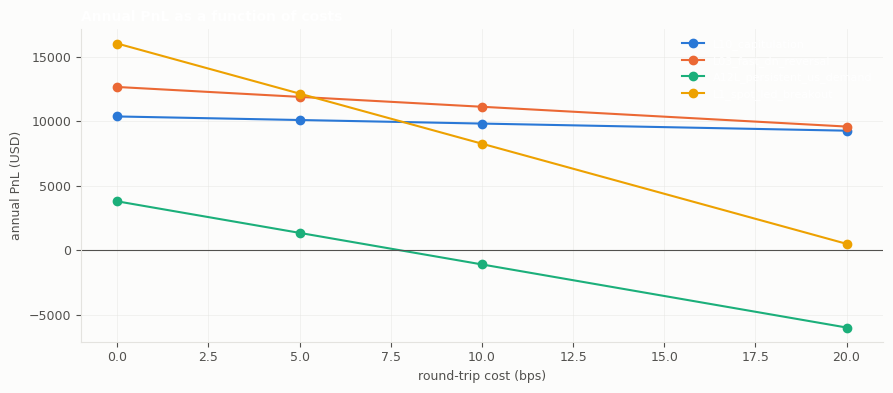

In [67]:
rows = {}
years_full = (end - start).days / 365.25
for c in COST_SCENARIOS_BPS:
    g = TRADES.assign(r=TRADES.gross_ret - c / 1e4).groupby("strategy").r
    rows[f"{c} bps"] = (g.sum() * TRADE_NOTIONAL / years_full).reindex(NAMES)
COSTS = pd.DataFrame(rows)
print("Annual PnL (USD) after costs, full period:"); print(COSTS.round(0).to_string())
print("\nBreak-even cost (bps round trip) = mean gross return per trade:")
print((TRADES.groupby("strategy").gross_ret.mean() * 1e4).reindex(NAMES).round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
for n in NAMES:
    ax.plot(COST_SCENARIOS_BPS, COSTS.loc[n].values, marker="o", ms=6, color=COLOR[n], label=n)
ax.axhline(0, color="#52514e", lw=0.8); ax.set_xlabel("round-trip cost (bps)"); ax.set_ylabel("annual PnL (USD)")
ax.set_title("Annual PnL as a function of costs", loc="left"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 14. Export for meta-labeling

The signals, with `side` and `t1`, for your filtering step. `t1` is needed for purged CV and for average uniqueness. The meta label is kept as in the original notebook (`gross_ret > 0`); a net-of-fees label is added as `meta_label_net` (`net_ret > 0`).

In [68]:
SIGNALS = TRADES[["t0", "t1", "strategy", "side", "ret", "t_value", "bin", "gross_ret", "net_ret", "period"]].copy()
SIGNALS["meta_label"] = (SIGNALS.gross_ret > 0).astype(int)
SIGNALS["meta_label_net"] = (SIGNALS.net_ret > 0).astype(int)   # label net of fees
SIGNALS.to_parquet("primary_signals_with_fees.parquet")
print(SIGNALS.groupby(["strategy", "period"]).size().unstack().reindex(NAMES).to_string())
SIGNALS.head()

period                      dev  holdout
strategy                                
L10_capitulation            249       26
L03_fast_dn_reversal        681       84
A12L_persistent_us_demand  2103      336
L1_spot_led_breakout       3314      557


,t0,t1,strategy,side,ret,t_value,bin,gross_ret,net_ret,period,meta_label,meta_label_net
0,2021-09-07 08:32:28.793000+00:00,2021-09-07 15:08:35.113000+00:00,L10_capitulation,1,-0.223945,-3.871769,-1.0,-0.223945,-0.224945,dev,0,0
1,2021-09-07 08:44:11.725000+00:00,2021-09-07 15:08:53.225000+00:00,L10_capitulation,1,-0.219714,4.342293,1.0,-0.219714,-0.220714,dev,0,0
2,2021-09-07 14:47:15.418000+00:00,2021-09-07 16:18:43.534000+00:00,L10_capitulation,1,0.111939,-1.540804,-1.0,0.111939,0.110939,dev,1,1
3,2021-09-07 14:49:02.823000+00:00,2021-09-07 16:12:16.788000+00:00,L10_capitulation,1,0.121603,10.944133,1.0,0.121603,0.120603,dev,1,1
4,2021-09-07 14:59:39.732000+00:00,2021-09-07 16:12:16.788000+00:00,L10_capitulation,1,0.131028,-6.400733,-1.0,0.131028,0.130028,dev,1,1


## 15. Gross vs net: what changes when fees are applied

Same trades, same statistics function. `GROSS` = fee 0 (the original notebook), `NET` = fee `COST_BPS_ROUNDTRIP`.

In [69]:
TRADES_GROSS = TRADES.assign(net_ret=TRADES.gross_ret, pnl_usd=TRADE_NOTIONAL * TRADES.gross_ret)
KEYS = ["trades", "win rate", "mean / trade (bps)", "profit factor", "PnL / year (USD)", "annual return (% capital)",
        "annualised Sharpe", "max drawdown (% capital)", "PSR (SR* = 0)", f"DSR (N = {N_TRIALS})"]

comparison = {}
for pname, (a, b) in PERIODS.items():
    for label, T_ in (("GROSS", TRADES_GROSS), ("NET", TRADES)):
        for n in NAMES:
            s = stats(T_[(T_.strategy == n) & (T_.t0 >= a) & (T_.t0 <= b)], a, b)
            comparison[(pname, n, label)] = {k: s[k] for k in KEYS}
CMP = pd.DataFrame(comparison).T
CMP.index.names = ["period", "strategy", "fees"]
for pname in PERIODS:
    print(f"\n================ {pname}: gross vs net (fee {COST_BPS_ROUNDTRIP} bps round trip) ================")
    print(CMP.loc[pname].map(fmt).to_string())


================ FULL: gross vs net (fee 10.0 bps round trip) ================
                                   trades win rate mean / trade (bps) profit factor PnL / year (USD) annual return (% capital) annualised Sharpe max drawdown (% capital) PSR (SR* = 0) DSR (N = 78)
strategy                  fees                                                                                                                                                                      
L10_capitulation          GROSS    275.00     0.60             188.41          1.64        10,369.61                    103.70              1.23                  -113.32          0.99         0.39
L03_fast_dn_reversal      GROSS    765.00     0.57              82.63          1.25        12,650.44                    126.50              0.71                  -476.85          0.91         0.11
A12L_persistent_us_demand GROSS  2,439.00     0.54               7.79          1.03         3,803.78                     38.04      

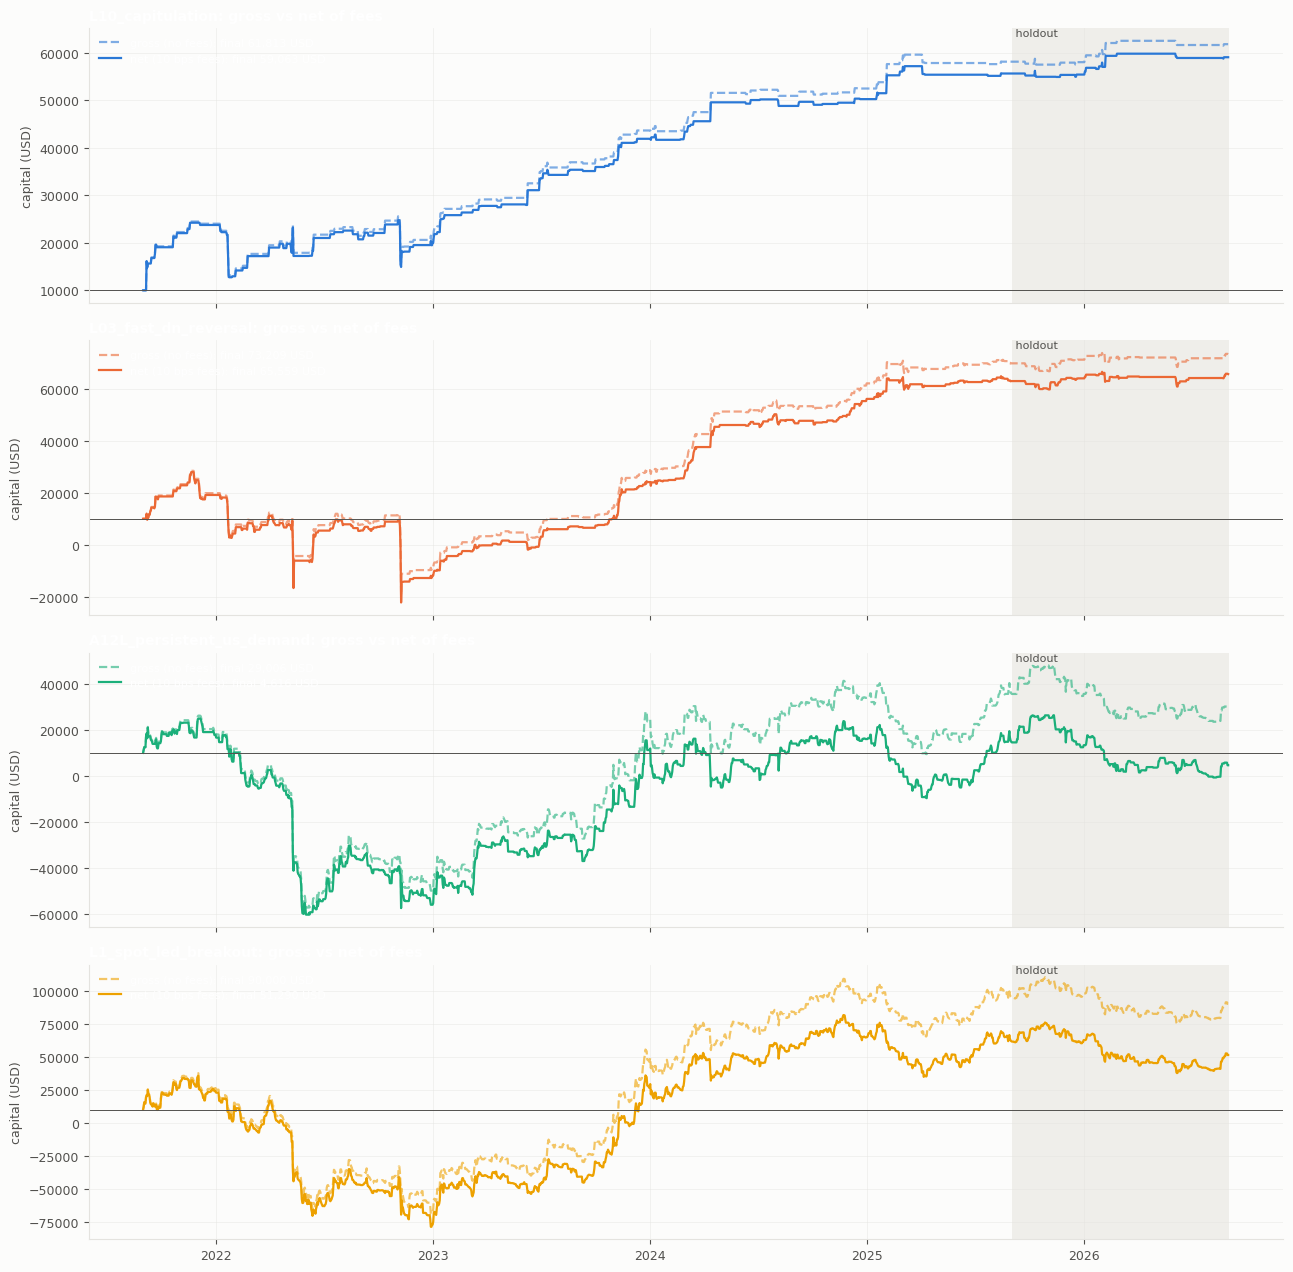

                          gross PnL (USD) fees paid (USD) net PnL (USD) fees / gross PnL
strategy                                                                                
L10_capitulation                51,812.56        2,750.00     49,062.56             0.05
L03_fast_dn_reversal            63,208.89        7,650.00     55,558.89             0.12
A12L_persistent_us_demand       19,005.87       24,390.00     -5,384.13             1.28
L1_spot_led_breakout            79,999.73       38,710.00     41,289.73             0.48


In [70]:
fig, axes = plt.subplots(len(NAMES), 1, figsize=(13, 3.2 * len(NAMES)), sharex=True)
for ax, n in zip(np.atleast_1d(axes), NAMES):
    for label, T_, ls in (("gross (no fees)", TRADES_GROSS, "--"), (f"net ({COST_BPS_ROUNDTRIP:g} bps fees)", TRADES, "-")):
        d = daily_pnl(T_[T_.strategy == n], start, end)
        eq = INITIAL_CAPITAL + d.cumsum()
        ax.plot(eq.index, eq.values, color=COLOR[n], lw=1.6, ls=ls, alpha=0.6 if ls == "--" else 1.0,
                label=f"{label}: final {eq.iloc[-1]:,.0f} USD")
    ax.axhline(INITIAL_CAPITAL, color="#52514e", lw=0.7)
    shade_holdout(ax)
    ax.set_ylabel("capital (USD)")
    ax.set_title(f"{n}: gross vs net of fees", loc="left")
    ax.legend(frameon=False, loc="upper left", fontsize=8)
np.atleast_1d(axes)[-1].xaxis.set_major_locator(mdates.YearLocator())
np.atleast_1d(axes)[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

fees_paid = TRADES.groupby("strategy").size() * TRADE_NOTIONAL * COST_BPS_ROUNDTRIP / 1e4
gross_pnl = TRADES_GROSS.groupby("strategy").pnl_usd.sum()
print(pd.DataFrame({"gross PnL (USD)": gross_pnl, "fees paid (USD)": fees_paid, "net PnL (USD)": gross_pnl - fees_paid,
                    "fees / gross PnL": fees_paid / gross_pnl}).reindex(NAMES).map(fmt).to_string())

## 16. Exit modes compared: trend-scanning `t1` vs fixed bars vs triple barrier

Same signals, same fees (`COST_BPS_ROUNDTRIP`), three exits. `ret` uses the ex-post trend-scanning window, so it is an optimistic reference; `fixed_bars` and `triple_barrier` are implementable.

In [71]:
MODES = ["ret", "fixed_bars", "triple_barrier"]
TR_BY_MODE = {m: build_trades(STRATEGIES, EVENTS, df, mode=m) for m in MODES}
KEYS_M = ["trades", "win rate", "mean / trade (bps)", "profit factor", "PnL / year (USD)",
          "annualised Sharpe", "max drawdown (% capital)", "PSR (SR* = 0)"]
rows = {}
for pname, (a, b) in PERIODS.items():
    for m in MODES:
        T_ = TR_BY_MODE[m]
        for n in NAMES:
            s = stats(T_[(T_.strategy == n) & (T_.t0 >= a) & (T_.t0 <= b)], a, b)
            rows[(pname, n, m)] = {k: s[k] for k in KEYS_M}
MODE_CMP = pd.DataFrame(rows).T
MODE_CMP.index.names = ["period", "strategy", "exit"]
for pname in PERIODS:
    print(f"\n================ {pname}: exit modes compared (net of {COST_BPS_ROUNDTRIP:g} bps fees) ================")
    print(MODE_CMP.loc[pname].map(fmt).to_string())

tb = TR_BY_MODE["triple_barrier"]
print("\nTriple barrier - exit reasons (% of trades) and mean net return by reason (bps):")
print(pd.concat({"% of trades": tb.groupby("strategy").exit_reason.value_counts(normalize=True).unstack() * 100,
                 "mean net bps": tb.groupby(["strategy", "exit_reason"]).net_ret.mean().unstack() * 1e4}, axis=1)
      .reindex(NAMES).round(1).to_string())


================ FULL: exit modes compared (net of 10 bps fees) ================
                                            trades win rate mean / trade (bps) profit factor PnL / year (USD) annualised Sharpe max drawdown (% capital) PSR (SR* = 0)
strategy                  exit                                                                                                                                        
L10_capitulation          ret               275.00     0.61              98.77          1.73         5,436.22              1.96                   -29.16          1.00
L03_fast_dn_reversal      ret               765.00     0.55              33.19          1.24         5,081.68              1.06                   -84.21          0.97
A12L_persistent_us_demand ret             2,441.00     0.51              -4.42          0.96        -2,159.49             -0.40                  -197.54          0.19
L1_spot_led_breakout      ret             3,874.00     0.50              -5.89     

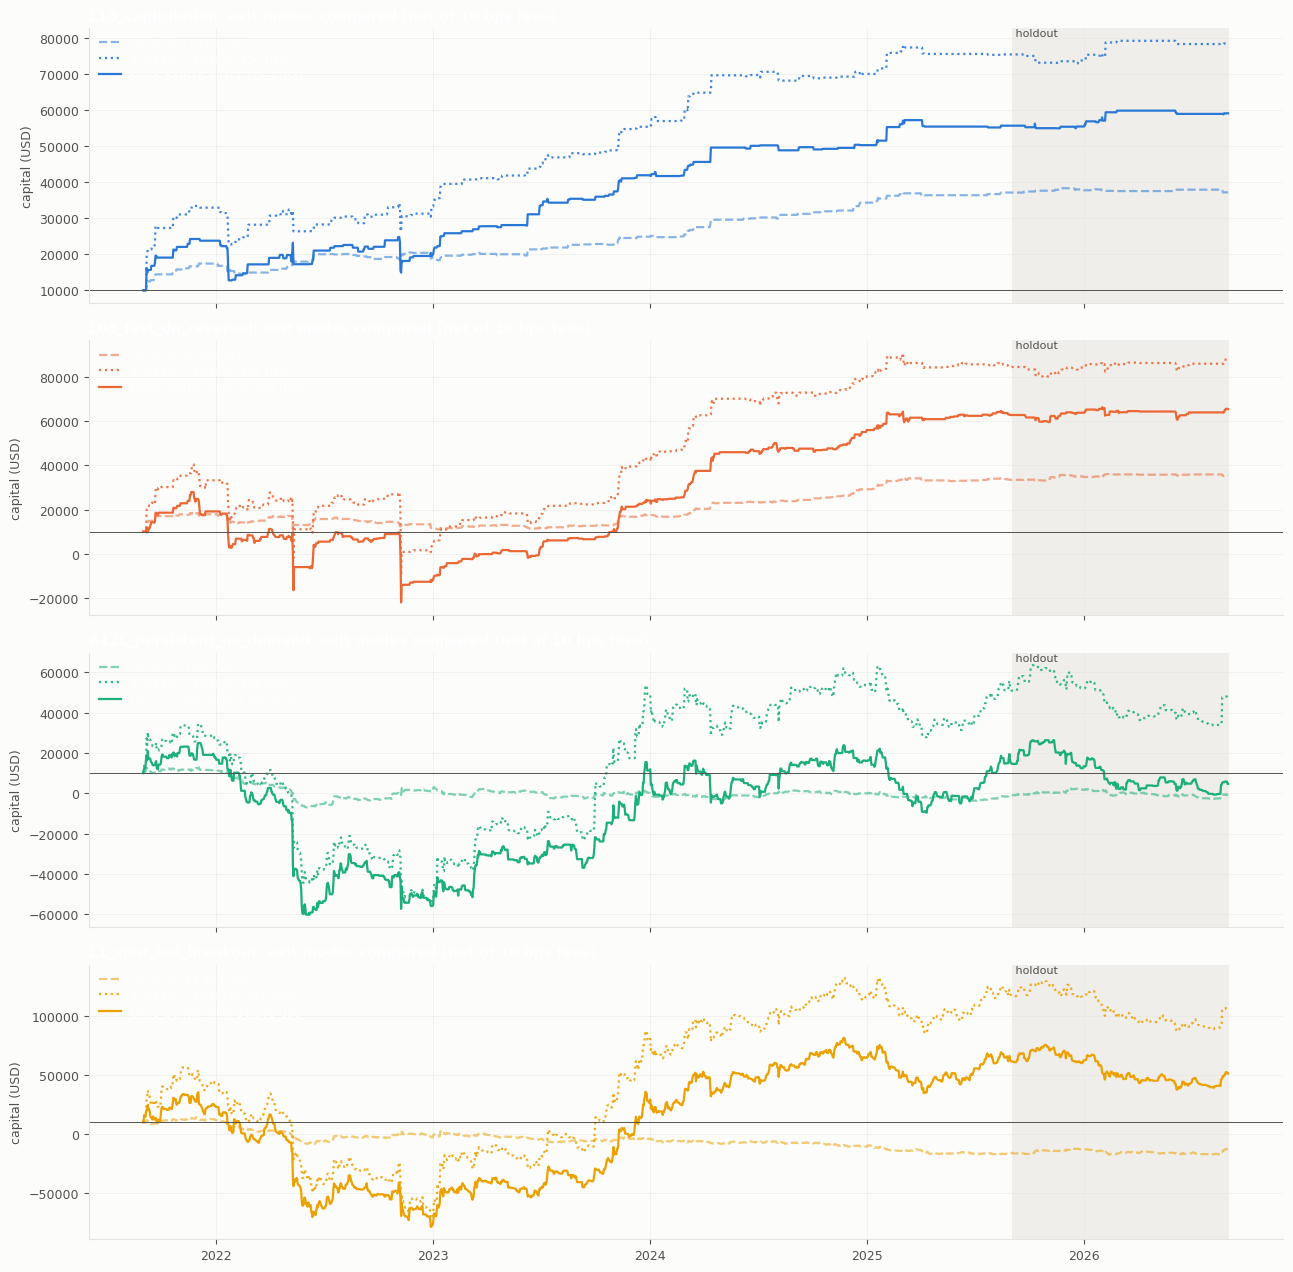

In [72]:
STYLE = {"ret": ("--", 0.55), "fixed_bars": (":", 0.9), "triple_barrier": ("-", 1.0)}
fig, axes = plt.subplots(len(NAMES), 1, figsize=(13, 3.2 * len(NAMES)), sharex=True)
for ax, n in zip(np.atleast_1d(axes), NAMES):
    for m in MODES:
        d = daily_pnl(TR_BY_MODE[m][TR_BY_MODE[m].strategy == n], start, end)
        eq = INITIAL_CAPITAL + d.cumsum()
        ls, al = STYLE[m]
        ax.plot(eq.index, eq.values, color=COLOR[n], ls=ls, alpha=al, lw=1.6, label=f"{m}: final {eq.iloc[-1]:,.0f} USD")
    ax.axhline(INITIAL_CAPITAL, color="#52514e", lw=0.7)
    shade_holdout(ax)
    ax.set_ylabel("capital (USD)")
    ax.set_title(f"{n}: exit modes compared (net of {COST_BPS_ROUNDTRIP:g} bps fees)", loc="left")
    ax.legend(frameon=False, loc="upper left", fontsize=8)
np.atleast_1d(axes)[-1].xaxis.set_major_locator(mdates.YearLocator())
np.atleast_1d(axes)[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()